# Tugas praktikum : K-Means dan DBSCAN data kafe

In [1]:
# Tugas 1: menyiapkan data K-Means
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn import metrics
df = pd.read_csv('../../dataset_pbl/cafes.csv')
X = df[['rating', 'review_count']].to_numpy()

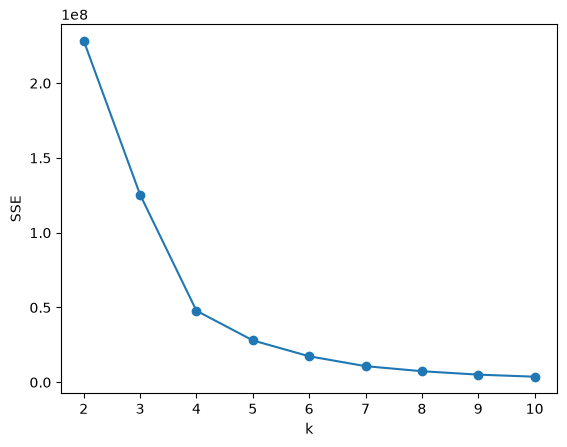

k berdasarkan silhouette tertinggi: 2


In [2]:
# Menentukan k menggunakan elbow dan silhouette seperti contoh tugas JS04
sse, scores = [], []
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42).fit(X)
    sse.append(model.inertia_)
    scores.append(metrics.silhouette_score(X, model.labels_))
plt.plot(range(2, 11), sse, 'o-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.show()
best_k = list(range(2, 11))[np.argmax(scores)]
print('k berdasarkan silhouette tertinggi:', best_k)

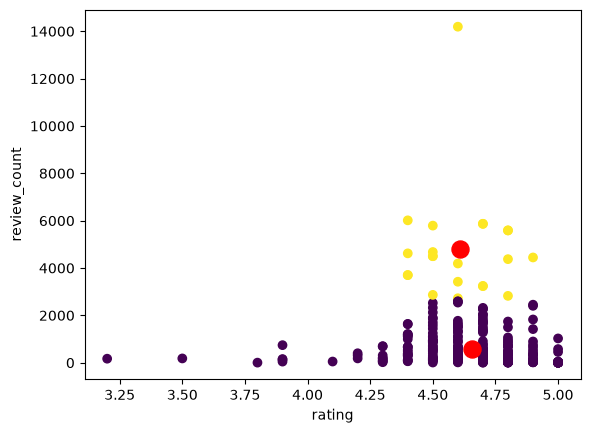

In [3]:
model = KMeans(n_clusters=best_k, random_state=42).fit(X)
plt.scatter(X[:, 0], X[:, 1], c=model.labels_)
plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], c='red', s=150)
plt.xlabel('rating')
plt.ylabel('review_count')
plt.show()

In [4]:
# Tugas 2: data PBL menggantikan make_moons
import pandas as pd
df = pd.read_csv('../../dataset_pbl/cafes.csv')
X = df[['latitude', 'longitude']].to_numpy()
labels_true = pd.factorize(df['source_query'].fillna('Tidak tersedia'))[0]
X_norm = StandardScaler().fit_transform(X)
y_asli = labels_true

In [5]:
def cek_metrik(X, y_asli, label):
    return {
        'Klaster': len(set(label)) - (1 if -1 in label else 0),
        'Noise': list(label).count(-1),
        'Homogeneity': metrics.homogeneity_score(y_asli, label),
        'Completeness': metrics.completeness_score(y_asli, label),
        'V-measure': metrics.v_measure_score(y_asli, label),
        'ARI': metrics.adjusted_rand_score(y_asli, label),
        'AMI': metrics.adjusted_mutual_info_score(y_asli, label),
        'Silhouette': metrics.silhouette_score(X, label) if 1 < len(set(label)) < len(X) else None,
    }

In [6]:
dbscan = DBSCAN(eps=0.2, min_samples=5).fit(X_norm)
label_dasar = dbscan.labels_
print(cek_metrik(X_norm, y_asli, label_dasar))

{'Klaster': 12, 'Noise': 90, 'Homogeneity': 0.5147921325303502, 'Completeness': 0.41527823172060674, 'V-measure': 0.45971138253191385, 'ARI': 0.19674530001162768, 'AMI': 0.41908955686721666, 'Silhouette': 0.16143390023876614}


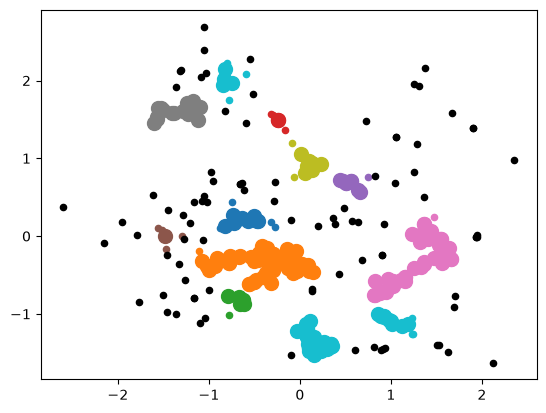

In [7]:
# Core besar, non-core kecil, dan noise hitam sesuai tugas
core = np.zeros(len(X_norm), dtype=bool)
core[dbscan.core_sample_indices_] = True
for label in set(label_dasar):
    anggota = label_dasar == label
    color = 'black' if label == -1 else plt.cm.tab10(label)
    for mask, size in [(anggota & core, 100), (anggota & ~core, 20)]:
        plt.scatter(X_norm[mask, 0], X_norm[mask, 1], color=color, s=size)
plt.show()

In [8]:
hasil = []
for eps in [0.05, 0.1, 0.3, 0.5]:
    for min_samples in [3, 10, 20]:
        label = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_norm)
        hasil.append({'eps': eps, 'min_samples': min_samples, **cek_metrik(X_norm, y_asli, label)})
pd.DataFrame(hasil)

,eps,min_samples,Klaster,Noise,Homogeneity,Completeness,V-measure,ARI,AMI,Silhouette
0,0.05,3,21,214,0.277631,0.324573,0.299272,0.106335,0.193614,-0.301380
1,0.05,10,0,302,0.000000,1.000000,0.000000,0.000000,0.000000,NaN
2,0.05,20,0,302,0.000000,1.000000,0.000000,0.000000,0.000000,NaN
3,0.10,3,28,116,0.510214,0.341371,0.409054,0.132403,0.315650,0.108143
4,0.10,10,1,287,0.042666,0.372234,0.076557,0.017423,0.065204,-0.227335
5,0.10,20,0,302,0.000000,1.000000,0.000000,0.000000,0.000000,NaN
6,0.30,3,7,11,0.380965,0.555356,0.451920,0.276855,0.423959,0.104247
7,0.30,10,7,74,0.506008,0.473570,0.489252,0.250459,0.465879,0.199695
8,0.30,20,3,194,0.292487,0.488632,0.365933,0.140825,0.350736,0.054475
9,0.50,3,2,3,0.024369,0.274453,0.044763,0.010985,0.023660,0.281565
